### Machine Learning - Assignment 1: Unsupervised Learning | Exercise 3


In [1]:
import matplotlib.pyplot as plt
import numpy as np

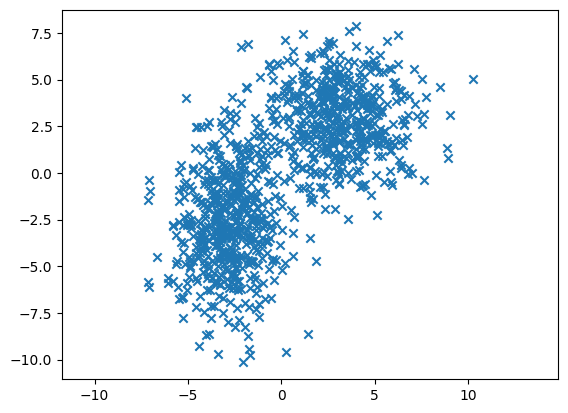

In [2]:
points = np.genfromtxt('data.csv', delimiter=',')

plt.scatter(points[:, 0], points[:, 1], marker="x")
plt.axis("equal")
plt.show()

In [3]:
points_copy = points.copy()
X = points[:, :2]

epsilon = 0.75
minimum_points = 5

visited = set()
assigned = set()

# 1. growing clusters
# 2. finalizing clusters
# -> repeat until all points are visited

clusters = []
while len(visited) != len(X):
    # 1. growing clusters
    # pick a random point that has not been visited yet
    point_index = np.random.choice(np.arange(len(X)), size=1, replace=False)[0]
    while point_index in visited:
        point_index = np.random.choice(np.arange(len(X)), size=1, replace=False)[0]
    visited.add(point_index)

    # find all points within epsilon distance of the chosen point
    distances = np.linalg.norm(X - X[point_index], axis=1)
    neighbors = np.where(distances <= epsilon)[0]

    # if the number of neighbors is less than minimum_points, mark the point as noise
    # (for now -> it can still join a cluster later as a border point)
    if len(neighbors) < minimum_points:
        continue

    # otherwise, create a new cluster and add the chosen point and its neighbors to it
    cluster = set(neighbors) - assigned
    frontier = set(cluster)  # points whose neighborhood still has to be checked

    # keep adding neighbors of CORE points until no more can be added
    while frontier:
        new_neighbors = set()
        for neighbor in frontier:
            distances = np.linalg.norm(X - X[neighbor], axis=1)
            neighbor_neighbors = np.where(distances <= epsilon)[0]
            if len(neighbor_neighbors) >= minimum_points:  # only core points extend the cluster
                new_neighbors.update(neighbor_neighbors)

        new_neighbors -= cluster
        new_neighbors -= assigned
        cluster.update(new_neighbors)
        frontier = new_neighbors

    # 2. finalizing clusters
    clusters.append(cluster)
    assigned.update(cluster)
    visited.update(cluster)

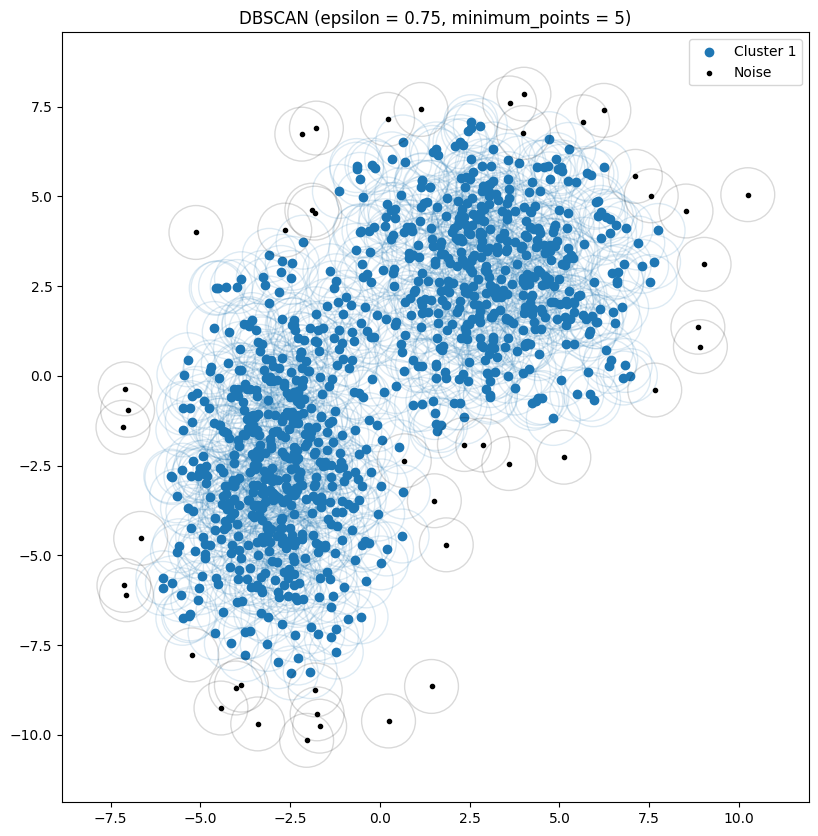

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for i, cluster in enumerate(clusters):
    color = colors[i % len(colors)]
    cluster_points = X[list(cluster)]
    ax.scatter(cluster_points[:, 0], cluster_points[:, 1], marker="o", color=color, label=f'Cluster {i+1}')
    for point in cluster_points:
        ax.add_patch(plt.Circle(point, epsilon, color=color, fill=False, alpha=0.15))

noise = np.array(sorted(set(range(len(X))) - assigned))
ax.scatter(X[noise, 0], X[noise, 1], c="black", marker=".", label="Noise")
for point in X[noise]:
    ax.add_patch(plt.Circle(point, epsilon, color="black", fill=False, alpha=0.15))

ax.set_aspect("equal")
ax.set_title(f"DBSCAN (epsilon = {epsilon}, minimum_points = {minimum_points})")
ax.legend()
plt.show()